# 01. Exploratory Data Analysis: French National Electricity Load

This notebook explores historical half-hourly electricity consumption and official RTE forecasts in France.
I analyze data from delivery day 2021-03-23 through 2024-12-31 Europe/Paris, reading the clean relation configured by `LFF_CLEAN_TABLE` (default `analytics.load_30min`) as `lff_agent`.

Following Protocol D4, all benchmark performance metrics for RTE D-1 are strictly confined to validation year 2024. The test year 2025 is locked and excluded from this analysis.


## 1. Environment and Data Loading

I load environment credentials, connect to PostgreSQL as role `lff_agent`, and retrieve clean half-hourly records. Reusable loading logic resides in `src/load_forecast/clean_data.py`, while evaluation metrics and calendar functions come from `src/load_forecast/evaluation.py`.


In [1]:
import sys
from pathlib import Path

# Ensure src is on sys.path regardless of execution working directory
repo_root = Path.cwd().resolve()
if repo_root.name == "notebooks":
    repo_root = repo_root.parent
src_path = str(repo_root / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

In [2]:
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from load_forecast.clean_data import load_clean_load
from load_forecast.database import clean_query
from load_forecast.eco2mix import connect_database
from load_forecast.evaluation import get_season, holidays, metrics

# Configure plot style per the project plot style (original contract section 7)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.edgecolor"] = "#cccccc"
plt.rcParams["grid.color"] = "#eeeeee"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

BLUE_ACCENT = "#1f4e9c"
GREY_REF = "#7f7f7f"
LIGHT_GREY = "#d0d0d0"
PARIS_TZ = ZoneInfo("Europe/Paris")


In [3]:
# Load clean half-hourly dataset up to 2024-12-31 Europe/Paris
end_validation = datetime(2025, 1, 1, 0, 0, tzinfo=PARIS_TZ)

with connect_database() as conn:
    df = load_clean_load(conn, end_time=end_validation)

print(f"Loaded {len(df):,} rows from the clean relation.")
print(f"Time range (UTC): {df['value_time'].min()} to {df['value_time'].max()}")
print(f"Time range (Paris): {df['value_time'].dt.tz_convert(PARIS_TZ).min()} to {df['value_time'].dt.tz_convert(PARIS_TZ).max()}")
print(f"Missing consumption count: {df['consommation'].isna().sum()}")
print(f"Missing RTE D-1 forecast count: {df['prevision_j1'].isna().sum()}")


Loaded 66,232 rows from the clean relation.
Time range (UTC): 2021-03-22 23:00:00+00:00 to 2024-12-31 22:30:00+00:00
Time range (Paris): 2021-03-23 00:00:00+01:00 to 2024-12-31 23:30:00+01:00
Missing consumption count: 0
Missing RTE D-1 forecast count: 0


In [4]:
# Add Paris local calendar features
df["paris_time"] = df["value_time"].dt.tz_convert(PARIS_TZ)
df["paris_date"] = df["paris_time"].dt.date
df["year"] = df["paris_time"].dt.year
df["month"] = df["paris_time"].dt.month
df["day"] = df["paris_time"].dt.day
df["hour"] = df["paris_time"].dt.hour
df["minute"] = df["paris_time"].dt.minute
df["weekday"] = df["paris_time"].dt.dayofweek  # 0=Monday, 6=Sunday
df["weekday_name"] = df["paris_time"].dt.strftime("%A")
df["time_slot"] = df["paris_time"].dt.strftime("%H:%M")
df["season"] = df["month"].apply(get_season)

# Identify national public holidays (Protocol D7)
holiday_dates = set()
for yr in df["year"].unique():
    holiday_dates |= set(holidays(int(yr)))

# Vectorized day categorization
is_weekday = df["weekday"] < 5
is_sat = df["weekday"] == 5
is_hol = df["paris_date"].isin(holiday_dates)

df["is_holiday"] = is_hol
df["day_category"] = "Sunday"
df.loc[is_sat, "day_category"] = "Saturday"
df.loc[is_weekday, "day_category"] = "Regular Weekday"
df.loc[is_weekday & is_hol, "day_category"] = "Weekday Holiday"
df.head(3)


,value_time,consommation,prevision_j1,prevision_j,source_dataset,paris_time,paris_date,year,month,day,hour,minute,weekday,weekday_name,time_slot,season,is_holiday,day_category
0,2021-03-22 23:00:00+00:00,62389,62900,62600,eco2mix-national-cons-def,2021-03-23 00:00:00+01:00,2021-03-23,2021,3,23,0,0,1,Tuesday,00:00,spring,False,Regular Weekday
1,2021-03-22 23:30:00+00:00,61177,61400,61200,eco2mix-national-cons-def,2021-03-23 00:30:00+01:00,2021-03-23,2021,3,23,0,30,1,Tuesday,00:30,spring,False,Regular Weekday
2,2021-03-23 00:00:00+00:00,59150,59600,59600,eco2mix-national-cons-def,2021-03-23 01:00:00+01:00,2021-03-23,2021,3,23,1,0,1,Tuesday,01:00,spring,False,Regular Weekday


## 2. Consumption Over the Whole Period

I inspect the complete consumption trajectory from March 2021 through December 2024. I aggregate half-hourly load into daily average, minimum, and peak demand to highlight long-term trends and seasonal swings.


Overall peak load: 87.0 GW (86,978 MW) on 2022-01-14 09:30 Paris (Friday)
Overall minimum trough: 29.8 GW (29,798 MW) on 2023-06-04 06:00 Paris (Sunday)
Peak-to-trough ratio: 2.92
Winter mean load: 63.0 GW, Summer mean load: 43.0 GW
Winter to summer mean ratio: 1.47


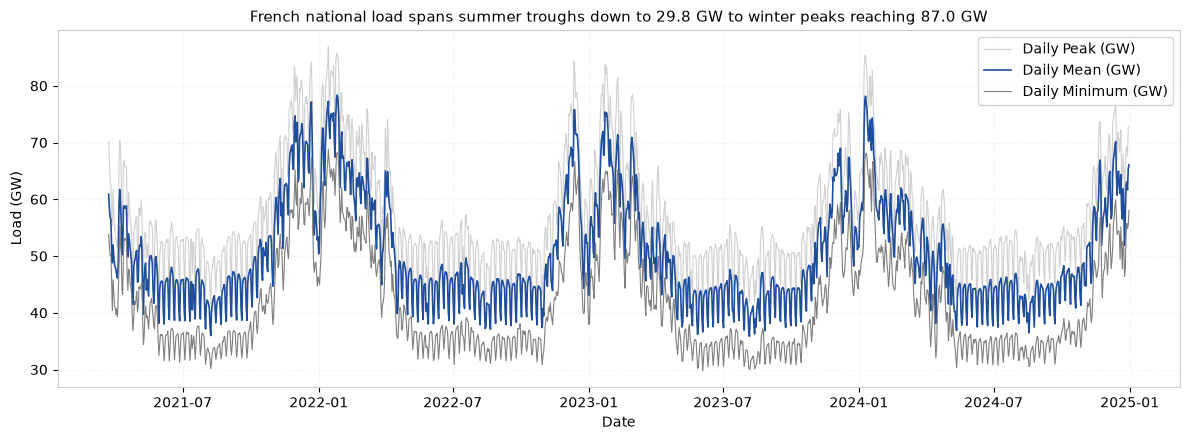

In [5]:
# Aggregate daily load metrics (GW)
daily_stats = df.groupby("paris_date").agg(
    mean_gw=("consommation", lambda s: s.mean() / 1000.0),
    max_gw=("consommation", lambda s: s.max() / 1000.0),
    min_gw=("consommation", lambda s: s.min() / 1000.0),
).reset_index()
daily_stats["paris_date"] = pd.to_datetime(daily_stats["paris_date"])

overall_peak = daily_stats["max_gw"].max()
overall_trough = daily_stats["min_gw"].min()
season_means = df.groupby("season")["consommation"].mean() / 1000.0
winter_summer_ratio = season_means["winter"] / season_means["summer"]

# Exact peak and trough half-hour slots
max_slot_idx = df["consommation"].idxmax()
min_slot_idx = df["consommation"].idxmin()
peak_row = df.loc[max_slot_idx]
trough_row = df.loc[min_slot_idx]
peak_time_paris = peak_row["paris_time"].strftime("%Y-%m-%d %H:%M Paris (%A)")
trough_time_paris = trough_row["paris_time"].strftime("%Y-%m-%d %H:%M Paris (%A)")

print(f"Overall peak load: {overall_peak:.1f} GW ({peak_row['consommation']:,} MW) on {peak_time_paris}")
print(f"Overall minimum trough: {overall_trough:.1f} GW ({trough_row['consommation']:,} MW) on {trough_time_paris}")
print(f"Peak-to-trough ratio: {overall_peak / overall_trough:.2f}")
print(f"Winter mean load: {season_means['winter']:.1f} GW, Summer mean load: {season_means['summer']:.1f} GW")
print(f"Winter to summer mean ratio: {winter_summer_ratio:.2f}")

fig, ax = plt.subplots(figsize=(12, 4.5), dpi=100)
ax.plot(daily_stats["paris_date"], daily_stats["max_gw"], color=LIGHT_GREY, label="Daily Peak (GW)", lw=0.8)
ax.plot(daily_stats["paris_date"], daily_stats["mean_gw"], color=BLUE_ACCENT, label="Daily Mean (GW)", lw=1.2)
ax.plot(daily_stats["paris_date"], daily_stats["min_gw"], color=GREY_REF, label="Daily Minimum (GW)", lw=0.8)

ax.set_title(f"French national load spans summer troughs down to {overall_trough:.1f} GW to winter peaks reaching {overall_peak:.1f} GW")
ax.set_xlabel("Date")
ax.set_ylabel("Load (GW)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
plt.show()

Consistent with strong thermo-sensitivity, winter mean demand (63.0 GW) reaches 1.47 times summer mean demand (43.0 GW), with peak load reaching 87.0 GW (86,978 MW on 2022-01-14 09:30 Paris) down to a summer trough of 29.8 GW (29,798 MW on 2023-06-04 06:00 Paris). High electric heating sensitivity is a key hypothesis to test with temperature data.

## 3. Daily and Weekly Profiles by Season

I analyze intraday and day-of-week demand patterns across the four meteorological seasons: winter (Dec-Feb), spring (Mar-May), summer (Jun-Aug), and autumn (Sep-Nov).

Winter minus summer mean shift: 20.1 GW
Winter minus summer shift range: 16.1 GW (at 16:00) to 24.5 GW (at 07:30)
Winter peak slot: 19:30 at 69.1 GW
Summer evening peak: 19:00 at 46.3 GW (vs 45.2 GW at 18:00 and 45.7 GW at 20:00)


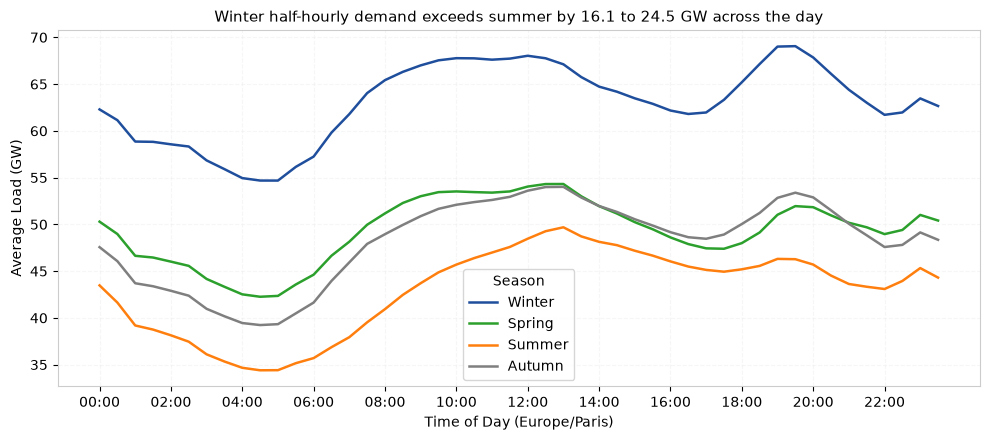

In [6]:
# Compute average half-hourly daily profile by season (GW)
season_order = ["winter", "spring", "summer", "autumn"]
season_colors = {
    "winter": BLUE_ACCENT,
    "spring": "#2ca02c",
    "summer": "#ff7f0e",
    "autumn": GREY_REF,
}

daily_season_profiles = df.groupby(["season", "time_slot"])["consommation"].mean().unstack(level=0) / 1000.0
daily_season_profiles = daily_season_profiles[season_order]

w_s_diff = daily_season_profiles["winter"] - daily_season_profiles["summer"]
mean_shift = w_s_diff.mean()
min_shift = w_s_diff.min()
max_shift = w_s_diff.max()
winter_peak_slot = daily_season_profiles["winter"].idxmax()
winter_peak_val = daily_season_profiles["winter"].max()

summer_profile = daily_season_profiles["summer"]
summer_eve = summer_profile.loc["17:00":"22:00"]
summer_peak_slot = summer_eve.idxmax()
summer_peak_val = summer_eve.max()

print(f"Winter minus summer mean shift: {mean_shift:.1f} GW")
print(f"Winter minus summer shift range: {min_shift:.1f} GW (at {w_s_diff.idxmin()}) to {max_shift:.1f} GW (at {w_s_diff.idxmax()})")
print(f"Winter peak slot: {winter_peak_slot} at {winter_peak_val:.1f} GW")
print(f"Summer evening peak: {summer_peak_slot} at {summer_peak_val:.1f} GW (vs {summer_profile['18:00']:.1f} GW at 18:00 and {summer_profile['20:00']:.1f} GW at 20:00)")

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=100)
for season in season_order:
    ax.plot(daily_season_profiles.index, daily_season_profiles[season], label=season.capitalize(), color=season_colors[season], lw=1.8)

ax.set_title(f"Winter half-hourly demand exceeds summer by {min_shift:.1f} to {max_shift:.1f} GW across the day")
ax.set_xlabel("Time of Day (Europe/Paris)")
ax.set_ylabel("Average Load (GW)")
ax.set_xticks(range(0, 48, 4))
ax.set_xticklabels(daily_season_profiles.index[::4], rotation=0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Season", frameon=True)
plt.tight_layout()
plt.show()

Daily demand exhibits morning and evening peaks across all seasons. Winter peaks at 19:30 (69.1 GW), while summer reaches an evening peak at 19:00 (46.3 GW).

Regular weekday mean: 52.14 GW
Saturday mean: 47.44 GW (drop of 9.0%)
Sunday mean: 45.62 GW (drop of 12.5%, -6.52 GW)
Sunday drop in winter: 9.50% (regular 64.76 GW vs Sunday 58.61 GW)
Sunday drop in spring: 13.61% (regular 51.46 GW vs Sunday 44.45 GW)
Sunday drop in summer: 14.40% (regular 44.58 GW vs Sunday 38.16 GW)
Sunday drop in autumn: 13.39% (regular 49.86 GW vs Sunday 43.18 GW)


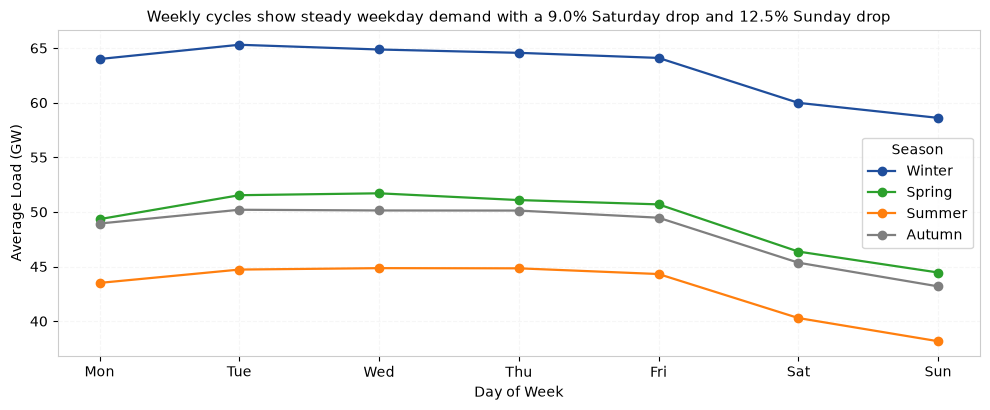

In [7]:
# Compute weekly load profile by season (GW)
dow_season = df.groupby(["season", "weekday"])["consommation"].mean().unstack(level=0) / 1000.0
dow_season = dow_season[season_order]
weekday_labels = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

reg_weekday_mean = df[df["day_category"] == "Regular Weekday"]["consommation"].mean() / 1000.0
sat_mean = df[df["day_category"] == "Saturday"]["consommation"].mean() / 1000.0
sun_mean = df[df["day_category"] == "Sunday"]["consommation"].mean() / 1000.0

sat_drop_pct = (reg_weekday_mean - sat_mean) / reg_weekday_mean * 100.0
sun_drop_pct = (reg_weekday_mean - sun_mean) / reg_weekday_mean * 100.0
sun_drop_gw = reg_weekday_mean - sun_mean

print(f"Regular weekday mean: {reg_weekday_mean:.2f} GW")
print(f"Saturday mean: {sat_mean:.2f} GW (drop of {sat_drop_pct:.1f}%)")
print(f"Sunday mean: {sun_mean:.2f} GW (drop of {sun_drop_pct:.1f}%, -{sun_drop_gw:.2f} GW)")

# Compute Sunday drops by season (relative to regular weekdays of the same season)
cat_season = df.groupby(["season", "day_category"])["consommation"].mean() / 1000.0
for s in season_order:
    reg_s = cat_season.loc[(s, "Regular Weekday")]
    sun_s = cat_season.loc[(s, "Sunday")]
    drop_pct = (reg_s - sun_s) / reg_s * 100.0
    print(f"Sunday drop in {s}: {drop_pct:.2f}% (regular {reg_s:.2f} GW vs Sunday {sun_s:.2f} GW)")

fig, ax = plt.subplots(figsize=(10, 4.2), dpi=100)
for season in season_order:
    ax.plot(weekday_labels, dow_season[season], marker="o", label=season.capitalize(), color=season_colors[season], lw=1.6)

ax.set_title(f"Weekly cycles show steady weekday demand with a {sat_drop_pct:.1f}% Saturday drop and {sun_drop_pct:.1f}% Sunday drop")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Average Load (GW)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Season", frameon=True)
plt.tight_layout()
plt.show()

Weekend demand drops substantially below weekday levels, with Sunday demand averaging 6.5 GW below regular weekdays across 2021 to 2024 (a 12.5% relative drop, ranging from 9.50% in winter to 14.40% in summer: 9.50% winter, 13.61% spring, 14.40% summer, 13.39% autumn).

## 4. Effect of Public Holidays and the 2022 Energy Crisis

I examine how non-standard calendar events and macroscopic macroeconomic shocks alter national power consumption.

Raw weekday holiday difference (unadjusted for season): 8.93 GW
Paired +/-14 days holiday effect: mean reduction = 6.54 GW across 32 weekday holidays
Paired +/-14 days Sunday effect: mean reduction = 6.45 GW across 197 Sundays


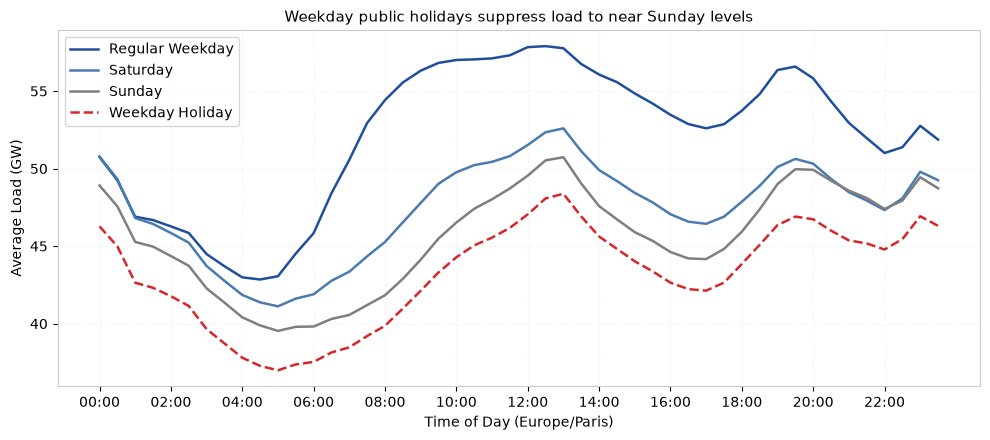

In [8]:
from datetime import timedelta

# Compare daily load profiles: Weekday vs Holiday vs Weekend
cat_order = ["Regular Weekday", "Saturday", "Sunday", "Weekday Holiday"]
cat_colors = {
    "Regular Weekday": BLUE_ACCENT,
    "Saturday": "#4a7bb0",
    "Sunday": GREY_REF,
    "Weekday Holiday": "#d62728",
}

cat_profiles = df.groupby(["day_category", "time_slot"])["consommation"].mean().unstack(level=0) / 1000.0
cat_profiles = cat_profiles[cat_order]

# 1. Unadjusted raw difference over whole period
raw_reg_mean = df[df["day_category"] == "Regular Weekday"]["consommation"].mean() / 1000.0
raw_hol_mean = df[df["day_category"] == "Weekday Holiday"]["consommation"].mean() / 1000.0
raw_diff = raw_reg_mean - raw_hol_mean

# 2. Seasonally-adjusted paired comparison (+/- 14 days)
daily_means = df.groupby("paris_date").agg(
    consommation=("consommation", "mean"),
    day_category=("day_category", "first"),
)
daily_means["load_gw"] = daily_means["consommation"] / 1000.0

weekday_hols = daily_means[daily_means["day_category"] == "Weekday Holiday"]
local_diffs = []
for hol_date, row in weekday_hols.iterrows():
    window_start = hol_date - timedelta(days=14)
    window_end = hol_date + timedelta(days=14)
    neighbors = daily_means[
        (daily_means.index >= window_start)
        & (daily_means.index <= window_end)
        & (daily_means["day_category"] == "Regular Weekday")
    ]
    if not neighbors.empty:
        local_diffs.append(neighbors["load_gw"].mean() - row["load_gw"])

sundays = daily_means[daily_means["day_category"] == "Sunday"]
sunday_diffs = []
for sun_date, row in sundays.iterrows():
    window_start = sun_date - timedelta(days=14)
    window_end = sun_date + timedelta(days=14)
    neighbors = daily_means[
        (daily_means.index >= window_start)
        & (daily_means.index <= window_end)
        & (daily_means["day_category"] == "Regular Weekday")
    ]
    if not neighbors.empty:
        sunday_diffs.append(neighbors["load_gw"].mean() - row["load_gw"])

paired_diff = float(np.mean(local_diffs))
paired_sunday_diff = float(np.mean(sunday_diffs))
print(f"Raw weekday holiday difference (unadjusted for season): {raw_diff:.2f} GW")
print(f"Paired +/-14 days holiday effect: mean reduction = {paired_diff:.2f} GW across {len(local_diffs)} weekday holidays")
print(f"Paired +/-14 days Sunday effect: mean reduction = {paired_sunday_diff:.2f} GW across {len(sunday_diffs)} Sundays")

fig, ax = plt.subplots(figsize=(10, 4.5), dpi=100)
for cat in cat_order:
    ax.plot(cat_profiles.index, cat_profiles[cat], label=cat, color=cat_colors[cat], lw=1.8, linestyle="--" if "Holiday" in cat else "-")

ax.set_title("Weekday public holidays suppress load to near Sunday levels")
ax.set_xlabel("Time of Day (Europe/Paris)")
ax.set_ylabel("Average Load (GW)")
ax.set_xticks(range(0, 48, 4))
ax.set_xticklabels(cat_profiles.index[::4], rotation=0)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

In a paired comparison against non-holiday weekdays within 14 days, weekday public holidays reduce demand by an average of 6.54 GW across 32 holidays (unadjusted raw gap is 8.93 GW), matching closely the paired Sunday reduction of 6.45 GW across 197 Sundays. Afternoon holiday load closely tracks Sunday profiles.

Q4 2021 average load: 58,884.9 MW
Q4 2022 average load: 51,958.9 MW
Q4 2023 average load: 52,689.3 MW
Q4 2024 average load: 54,202.2 MW
Q4 2022 vs 2021: -11.76%
Q4 2023 vs 2021: -10.52%
Q4 2024 vs 2021: -7.95%
Q4 2024 vs 2022: +4.32%


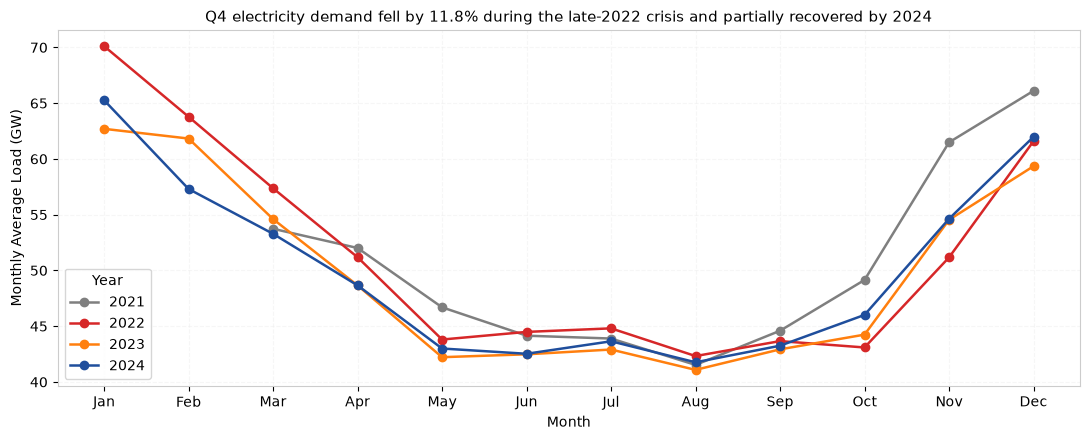

In [9]:
# Analyze the 2022 energy crisis impact across calendar years 2021 to 2024
crisis_years = [2021, 2022, 2023, 2024]
df_crisis = df[df["year"].isin(crisis_years)].copy()

monthly_yearly = df_crisis.groupby(["year", "month"])["consommation"].mean().unstack(level=0) / 1000.0
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Quantify Q4 load across years
q4_loads = {}
for yr in crisis_years:
    q4_val = df[(df["year"] == yr) & (df["month"].isin([10, 11, 12]))]["consommation"].mean()
    q4_loads[yr] = q4_val
    print(f"Q4 {yr} average load: {q4_val:,.1f} MW")

drop_22_vs_21 = 100.0 * (q4_loads[2022] - q4_loads[2021]) / q4_loads[2021]
drop_23_vs_21 = 100.0 * (q4_loads[2023] - q4_loads[2021]) / q4_loads[2021]
drop_24_vs_21 = 100.0 * (q4_loads[2024] - q4_loads[2021]) / q4_loads[2021]
rebound_24_vs_22 = 100.0 * (q4_loads[2024] - q4_loads[2022]) / q4_loads[2022]

print(f"Q4 2022 vs 2021: {drop_22_vs_21:.2f}%")
print(f"Q4 2023 vs 2021: {drop_23_vs_21:.2f}%")
print(f"Q4 2024 vs 2021: {drop_24_vs_21:.2f}%")
print(f"Q4 2024 vs 2022: +{rebound_24_vs_22:.2f}%")

fig, ax = plt.subplots(figsize=(11, 4.5), dpi=100)
year_colors = {2021: GREY_REF, 2022: "#d62728", 2023: "#ff7f0e", 2024: BLUE_ACCENT}
for yr in crisis_years:
    ax.plot(month_names, monthly_yearly[yr], marker="o", label=str(yr), color=year_colors[yr], lw=1.8)

ax.set_title(f"Q4 electricity demand fell by {abs(drop_22_vs_21):.1f}% during the late-2022 crisis and partially recovered by 2024")
ax.set_xlabel("Month")
ax.set_ylabel("Monthly Average Load (GW)")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(title="Year", frameon=True)
plt.tight_layout()
plt.show()


Q4 demand fell by 11.8% between 2021 and 2022, then showed a gradual partial recovery in 2023 (-10.5% vs 2021) and 2024 (-7.9% vs 2021, up 4.3% vs 2022). Price signals and sobriety measures are likely contributors, though temperature variations must be disentangled during modeling.


## 5. RTE D-1 Forecast Benchmark on Validation Year 2024

I evaluate RTE's official day-ahead forecast benchmark (`prevision_j1`) on the validation year 2024. All model experiments will compete against this benchmark on these identical timestamps.

Per the task contract, I demonstrate that the figures calculated here match the exact outputs of SQL queries run directly in PostgreSQL.

### 5.1 Overall Error on 2024

I query PostgreSQL to compute overall MAE, RMSE, and MAPE across 2024.
The validation period follows the Europe/Paris calendar year convention. Nominal calendar year 2024 contains 17,568 half-hour slots (366 days x 48 slots). Exactly 17,566 slots are scored: 2 slots on 2024-10-27 (00:00 and 00:30 UTC, 02:00 to 02:59 CEST) are absent rows in the source data for both actual consumption and RTE D-1 (the autumn gap of D12).

In [10]:
query_overall_2024 = clean_query("""
SELECT 
    count(*) AS n_slots,
    round(avg(abs(consommation - prevision_j1))::numeric, 2) AS mae_mw,
    round(sqrt(avg(power(consommation - prevision_j1, 2)))::numeric, 2) AS rmse_mw,
    round(avg(100.0 * abs(consommation - prevision_j1) / consommation)::numeric, 3) AS mape_pct
FROM {table}
WHERE (value_time AT TIME ZONE 'Europe/Paris')::date >= '2024-01-01'
  AND (value_time AT TIME ZONE 'Europe/Paris')::date <= '2024-12-31'
  AND consommation IS NOT NULL
  AND prevision_j1 IS NOT NULL;
""")

with connect_database() as conn:
    with conn.cursor() as cur:
        cur.execute(query_overall_2024)
        sql_ov_res = cur.fetchone()

print("SQL Query Result (Overall 2024):")
print(f"Slots: {sql_ov_res[0]:,}, MAE: {sql_ov_res[1]} MW, RMSE: {sql_ov_res[2]} MW, MAPE: {sql_ov_res[3]}%")

# Compute via Python metrics helper on loaded DataFrame (indexed by aware UTC value_time)
df_2024 = df[df["year"] == 2024].copy().set_index("value_time")
metrics_ov = metrics(df_2024["consommation"], df_2024["prevision_j1"])

print("\nPython Helper Result (Overall 2024):")
print(f"Slots: {metrics_ov.n_slots:,}, MAE: {metrics_ov.mae:.2f} MW, RMSE: {metrics_ov.rmse:.2f} MW, MAPE: {metrics_ov.mape:.3f}%")

assert metrics_ov.n_slots == sql_ov_res[0]
assert round(metrics_ov.mae, 2) == float(sql_ov_res[1])
assert round(metrics_ov.rmse, 2) == float(sql_ov_res[2])
assert round(metrics_ov.mape, 3) == float(sql_ov_res[3])
print("Verification: Python and SQL results match exactly!")


SQL Query Result (Overall 2024):
Slots: 17,566, MAE: 1364.58 MW, RMSE: 1701.57 MW, MAPE: 2.731%

Python Helper Result (Overall 2024):
Slots: 17,566, MAE: 1364.58 MW, RMSE: 1701.57 MW, MAPE: 2.731%
Verification: Python and SQL results match exactly!


RTE D-1 achieves an overall MAE of 1,364.58 MW and a MAPE of 2.731% across 17,566 validation slots in 2024 (2 absent slots on 2024-10-27 under the autumn gap of D12).

### 5.2 Monthly Error Breakdown

I query PostgreSQL for monthly errors and visualize the seasonal variation in RTE day-ahead predictability.

In [11]:
query_monthly_2024 = clean_query("""
SELECT 
    extract(month FROM value_time AT TIME ZONE 'Europe/Paris')::int AS month,
    count(*) AS n_slots,
    round(avg(abs(consommation - prevision_j1))::numeric, 2) AS mae_mw,
    round(sqrt(avg(power(consommation - prevision_j1, 2)))::numeric, 2) AS rmse_mw,
    round(avg(100.0 * abs(consommation - prevision_j1) / consommation)::numeric, 3) AS mape_pct
FROM {table}
WHERE (value_time AT TIME ZONE 'Europe/Paris')::date >= '2024-01-01'
  AND (value_time AT TIME ZONE 'Europe/Paris')::date <= '2024-12-31'
  AND consommation IS NOT NULL
  AND prevision_j1 IS NOT NULL
GROUP BY month
ORDER BY month;
""")

with connect_database() as conn:
    with conn.cursor() as cur:
        cur.execute(query_monthly_2024)
        sql_monthly_res = cur.fetchall()

monthly_df = pd.DataFrame(sql_monthly_res, columns=["month", "n_slots", "mae_mw", "rmse_mw", "mape_pct"])
monthly_df["month_name"] = month_names
monthly_df

,month,n_slots,mae_mw,rmse_mw,mape_pct,month_name
0,1,1488,1906.14,2312.63,2.936,Jan
1,2,1392,1588.95,1880.93,2.786,Feb
2,3,1486,1281.24,1563.67,2.448,Mar
3,4,1440,1566.20,1906.11,3.237,Apr
4,5,1488,1660.10,2017.81,3.868,May
5,6,1440,1230.57,1466.95,2.908,Jun
6,7,1488,1176.57,1456.79,2.659,Jul
7,8,1488,868.99,1092.74,2.082,Aug
8,9,1440,1200.49,1457.37,2.728,Sep
9,10,1488,1009.84,1228.88,2.197,Oct


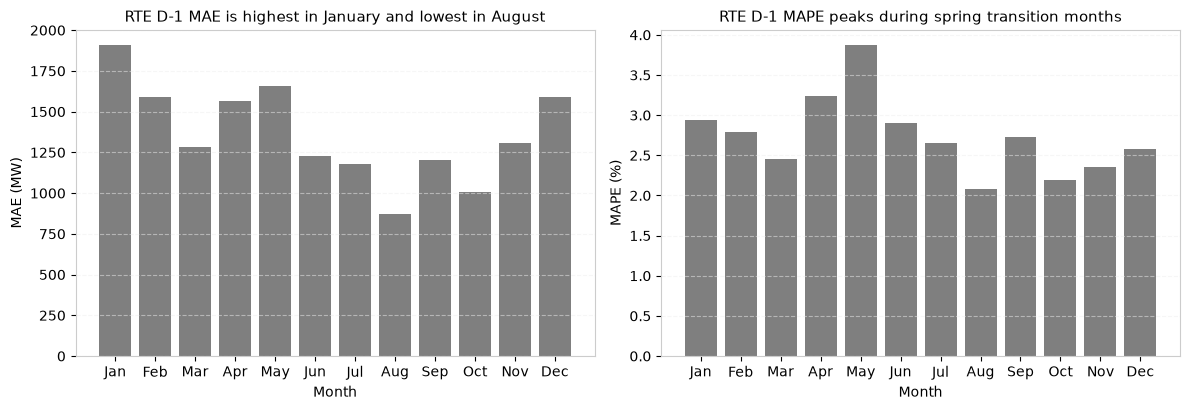

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), dpi=100)

ax1.bar(monthly_df["month_name"], monthly_df["mae_mw"], color=GREY_REF)
ax1.set_title("RTE D-1 MAE is highest in January and lowest in August")
ax1.set_xlabel("Month")
ax1.set_ylabel("MAE (MW)")
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")

ax2.bar(monthly_df["month_name"], monthly_df["mape_pct"], color=GREY_REF)
ax2.set_title("RTE D-1 MAPE peaks during spring transition months")
ax2.set_xlabel("Month")
ax2.set_ylabel("MAPE (%)")
ax2.grid(True, linestyle="--", alpha=0.5, axis="y")

plt.tight_layout()
plt.show()


RTE day-ahead MAE peaks in January (1,906.14 MW), while spring transition months like May (1,660.10 MW) and April (1,566.20 MW) also show high MAE and lead in MAPE (May 3.87%, April 3.24%). August has the lowest error (MAE 868.99 MW, MAPE 2.08%). Winter heating sensitivity and spring weather volatility are hypotheses to investigate.


### 5.3 Weekday Error Breakdown

I query PostgreSQL for errors grouped by day of week to examine forecasting accuracy across working days and weekends.

In [13]:
query_weekday_2024 = clean_query("""
SELECT 
    extract(isodow FROM value_time AT TIME ZONE 'Europe/Paris')::int AS weekday,
    count(*) AS n_slots,
    round(avg(abs(consommation - prevision_j1))::numeric, 2) AS mae_mw,
    round(sqrt(avg(power(consommation - prevision_j1, 2)))::numeric, 2) AS rmse_mw,
    round(avg(100.0 * abs(consommation - prevision_j1) / consommation)::numeric, 3) AS mape_pct
FROM {table}
WHERE (value_time AT TIME ZONE 'Europe/Paris')::date >= '2024-01-01'
  AND (value_time AT TIME ZONE 'Europe/Paris')::date <= '2024-12-31'
  AND consommation IS NOT NULL
  AND prevision_j1 IS NOT NULL
GROUP BY weekday
ORDER BY weekday;
""")

with connect_database() as conn:
    with conn.cursor() as cur:
        cur.execute(query_weekday_2024)
        sql_weekday_res = cur.fetchall()

weekday_df = pd.DataFrame(sql_weekday_res, columns=["weekday", "n_slots", "mae_mw", "rmse_mw", "mape_pct"])
weekday_df["weekday_name"] = weekday_labels
weekday_df

,weekday,n_slots,mae_mw,rmse_mw,mape_pct,weekday_name
0,1,2544,1227.41,1512.69,2.442,Mon
1,2,2544,1290.88,1623.32,2.471,Tue
2,3,2496,1289.11,1662.87,2.569,Wed
3,4,2496,1289.11,1602.38,2.483,Thu
4,5,2496,1469.88,1861.94,2.781,Fri
5,6,2496,1525.24,1835.80,3.177,Sat
6,7,2494,1464.56,1786.38,3.206,Sun


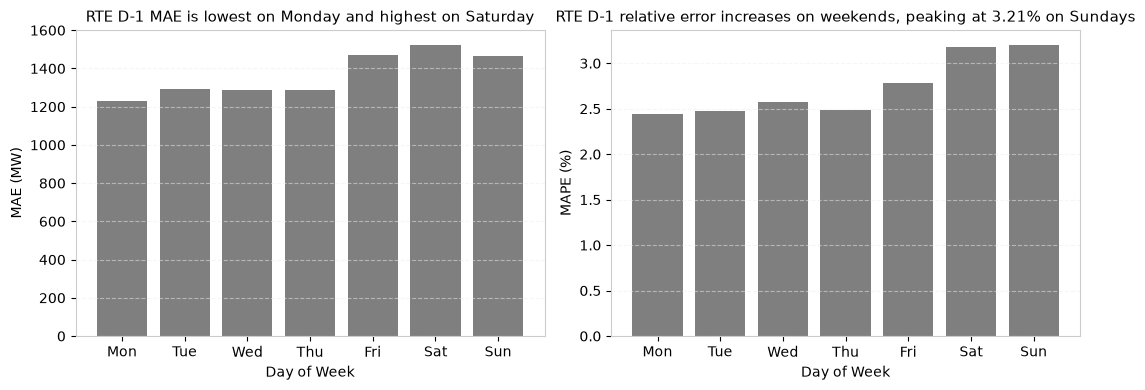

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.0), dpi=100)

ax1.bar(weekday_df["weekday_name"], weekday_df["mae_mw"], color=GREY_REF)
ax1.set_title("RTE D-1 MAE is lowest on Monday and highest on Saturday")
ax1.set_xlabel("Day of Week")
ax1.set_ylabel("MAE (MW)")
ax1.grid(True, linestyle="--", alpha=0.5, axis="y")

ax2.bar(weekday_df["weekday_name"], weekday_df["mape_pct"], color=GREY_REF)
ax2.set_title("RTE D-1 relative error increases on weekends, peaking at 3.21% on Sundays")
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("MAPE (%)")
ax2.grid(True, linestyle="--", alpha=0.5, axis="y")

plt.tight_layout()
plt.show()


RTE forecast error is lowest on Mondays (MAE 1,227.41 MW, MAPE 2.44%), while weekend days experience higher MAPE (Saturday 3.18%, Sunday 3.21%) and higher Saturday MAE (1,525.24 MW).


### 5.4 Hour-of-Day Error Breakdown

I query PostgreSQL for errors grouped by local hour of day to locate intraday forecasting challenges.

Peak afternoon MAE (15:00): 2038.02 MW, MAPE: 4.01%
Midnight MAE (00:00): 1941.59 MW, MAPE: 3.94%
Afternoon window MAE (13:00-16:00): exceeds 1915.23 MW (16:00 = 1915.23 MW)
Morning ramp MAE (05:00-07:00): under 869.33 MW (07:00 = 869.33 MW)


,hour_of_day,n_slots,mae_mw,rmse_mw,mape_pct
0,0,732,1941.59,2109.09,3.942
1,1,732,1277.37,1519.82,2.750
2,2,730,1165.73,1420.79,2.577
3,3,732,1478.41,1674.10,3.390
4,4,732,1200.69,1418.20,2.828
5,5,732,807.07,1035.67,1.888
6,6,732,785.97,998.28,1.796
7,7,732,869.33,1097.40,1.868
8,8,732,911.65,1180.30,1.803
9,9,732,1048.63,1349.07,1.975


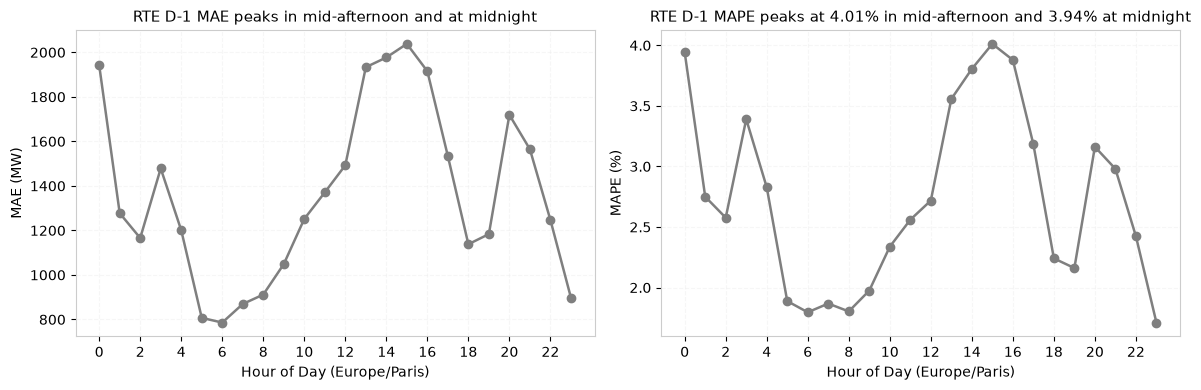

In [15]:
query_hour_2024 = clean_query("""
SELECT 
    extract(hour FROM value_time AT TIME ZONE 'Europe/Paris')::int AS hour_of_day,
    count(*) AS n_slots,
    round(avg(abs(consommation - prevision_j1))::numeric, 2) AS mae_mw,
    round(sqrt(avg(power(consommation - prevision_j1, 2)))::numeric, 2) AS rmse_mw,
    round(avg(100.0 * abs(consommation - prevision_j1) / consommation)::numeric, 3) AS mape_pct
FROM {table}
WHERE (value_time AT TIME ZONE 'Europe/Paris')::date >= '2024-01-01'
  AND (value_time AT TIME ZONE 'Europe/Paris')::date <= '2024-12-31'
  AND consommation IS NOT NULL
  AND prevision_j1 IS NOT NULL
GROUP BY hour_of_day
ORDER BY hour_of_day;
""")

with connect_database() as conn:
    with conn.cursor() as cur:
        cur.execute(query_hour_2024)
        sql_hour_res = cur.fetchall()

hour_df = pd.DataFrame(sql_hour_res, columns=["hour_of_day", "n_slots", "mae_mw", "rmse_mw", "mape_pct"])

mae_15 = hour_df.loc[hour_df["hour_of_day"] == 15, "mae_mw"].iloc[0]
mae_00 = hour_df.loc[hour_df["hour_of_day"] == 0, "mae_mw"].iloc[0]
mae_16 = hour_df.loc[hour_df["hour_of_day"] == 16, "mae_mw"].iloc[0]
mae_07 = hour_df.loc[hour_df["hour_of_day"] == 7, "mae_mw"].iloc[0]
mape_15 = hour_df.loc[hour_df["hour_of_day"] == 15, "mape_pct"].iloc[0]
mape_00 = hour_df.loc[hour_df["hour_of_day"] == 0, "mape_pct"].iloc[0]

print(f"Peak afternoon MAE (15:00): {mae_15:.2f} MW, MAPE: {mape_15:.2f}%")
print(f"Midnight MAE (00:00): {mae_00:.2f} MW, MAPE: {mape_00:.2f}%")
print(f"Afternoon window MAE (13:00-16:00): exceeds {hour_df.loc[hour_df['hour_of_day'].isin([13, 14, 15, 16]), 'mae_mw'].min():.2f} MW (16:00 = {mae_16:.2f} MW)")
print(f"Morning ramp MAE (05:00-07:00): under {hour_df.loc[hour_df['hour_of_day'].isin([5, 6, 7]), 'mae_mw'].max():.2f} MW (07:00 = {mae_07:.2f} MW)")
display(hour_df)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.0), dpi=100)

ax1.plot(hour_df["hour_of_day"], hour_df["mae_mw"], marker="o", color=GREY_REF, lw=1.8)
ax1.set_title("RTE D-1 MAE peaks in mid-afternoon and at midnight")
ax1.set_xlabel("Hour of Day (Europe/Paris)")
ax1.set_ylabel("MAE (MW)")
ax1.set_xticks(range(0, 24, 2))
ax1.grid(True, linestyle="--", alpha=0.5)

ax2.plot(hour_df["hour_of_day"], hour_df["mape_pct"], marker="o", color=GREY_REF, lw=1.8)
ax2.set_title(f"RTE D-1 MAPE peaks at {mape_15:.2f}% in mid-afternoon and {mape_00:.2f}% at midnight")
ax2.set_xlabel("Hour of Day (Europe/Paris)")
ax2.set_ylabel("MAPE (%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

RTE forecast MAE peaks at 15:00 (2,038.02 MW) and at midnight (1,941.59 MW), with the entire afternoon window (13:00 to 16:00) exceeding 1,915 MW (16:00 at 1,915.23 MW). In contrast, morning ramp hours (05:00 to 07:00) yield the lowest errors (under 870 MW, with 07:00 at 869.33 MW).

## 6. Summary of Key Findings for Modeling

1. High seasonal variation consistent with thermo-sensitivity: Winter mean demand (63.0 GW) is 1.47 times summer mean demand (43.0 GW), with peak load reaching 87.0 GW (2022-01-14 09:30 Paris) down to a summer trough of 29.8 GW (2023-06-04 06:00 Paris). High electric heating sensitivity is a core hypothesis to verify with weather data.
2. Distinct intraday and weekly cycles: Load exhibits clear double peaks (morning ramp and 19:30 evening peak of 69.1 GW in winter) and weekend dips (Sunday 12.5% below regular weekdays). Model formulations must capture hour-of-day, day-of-week, and seasonal interactions.
3. Holiday suppression: Weekday public holidays reduce demand by an average of 6.54 GW (season-adjusted) and behave similarly to Sundays (6.45 GW paired reduction). Holiday indicators are essential to prevent overprediction.
4. Structural crisis break: Demand dropped 11.8% in Q4 2022 relative to Q4 2021, recovering partially in 2023 (-10.5%) and 2024 (-7.9%). Adaptive online mechanisms (such as Kalman filtering on GAM effects) may be needed to handle macroeconomic shifts.
5. RTE benchmark target: The baseline to beat on validation year 2024 is an overall MAE of 1,364.58 MW (MAPE 2.731%), with largest errors concentrated in January (1,906 MW), spring transition months (April/May > 1,560 MW), and afternoon hours (13:00 to 16:00 > 1,915 MW) as well as midnight (1,942 MW).